In [2]:
import pandas as pd
import numpy as np
import os

In [3]:
df = pd.read_csv("waterQuality1.csv")

In [10]:
print("========== DATASET INFORMATION ==========")

print("\n1. Dataset Shape:")
print("Rows:", df.shape[0])
print("Columns:", df.shape[1])

print("\n2. Column Names:")
print(df.columns.tolist())

print("\n3. Data Types:")
print(df.dtypes)

print("\n4. Missing Values:")
print(df.isnull().sum())

print("\nTotal Missing Values:", df.isnull().sum().sum())

print("\n5. Duplicate Records:")
print("Duplicate Rows:", df.duplicated().sum())

print("\n6. Unique Values in Each Column:")
print(df.nunique())

print("\n7. Dataset Preview:")
display(df.head())

print("\n========== INSPECTION COMPLETED ==========")

========== DATASET INFORMATION ==========

1. Dataset Shape:
Rows: 7999
Columns: 21

2. Column Names:
['aluminium', 'ammonia', 'arsenic', 'barium', 'cadmium', 'chloramine', 'chromium', 'copper', 'flouride', 'bacteria', 'viruses', 'lead', 'nitrates', 'nitrites', 'mercury', 'perchlorate', 'radium', 'selenium', 'silver', 'uranium', 'is_safe']

3. Data Types:
aluminium      float64
ammonia            str
arsenic        float64
barium         float64
cadmium        float64
chloramine     float64
chromium       float64
copper         float64
flouride       float64
bacteria       float64
viruses        float64
lead           float64
nitrates       float64
nitrites       float64
mercury        float64
perchlorate    float64
radium         float64
selenium       float64
silver         float64
uranium        float64
is_safe            str
dtype: object

4. Missing Values:
aluminium      0
ammonia        0
arsenic        0
barium         0
cadmium        0
chloramine     0
chromium       0
copper

,aluminium,ammonia,arsenic,barium,cadmium,chloramine,chromium,copper,flouride,bacteria,...,lead,nitrates,nitrites,mercury,perchlorate,radium,selenium,silver,uranium,is_safe
0,1.65,9.08,0.04,2.85,0.007,0.35,0.83,0.17,0.05,0.20,...,0.054,16.08,1.13,0.007,37.75,6.78,0.08,0.34,0.02,1
1,2.32,21.16,0.01,3.31,0.002,5.28,0.68,0.66,0.90,0.65,...,0.100,2.01,1.93,0.003,32.26,3.21,0.08,0.27,0.05,1
2,1.01,14.02,0.04,0.58,0.008,4.24,0.53,0.02,0.99,0.05,...,0.078,14.16,1.11,0.006,50.28,7.07,0.07,0.44,0.01,0
3,1.36,11.33,0.04,2.96,0.001,7.23,0.03,1.66,1.08,0.71,...,0.016,1.41,1.29,0.004,9.12,1.72,0.02,0.45,0.05,1
4,0.92,24.33,0.03,0.20,0.006,2.67,0.69,0.57,0.61,0.13,...,0.117,6.74,1.11,0.003,16.90,2.41,0.02,0.06,0.02,1



========== INSPECTION COMPLETED ==========


In [11]:
print("Invalid values in ammonia:")
print(df["ammonia"].value_counts())

print("\nValues in is_safe:")
print(df["is_safe"].value_counts())

print("\nData types:")
print(df.dtypes)

Invalid values in ammonia:
ammonia
0.12     13
0.37     13
0.17     13
13.74    12
21.58    11
         ..
15.35     1
6.87      1
2.78      1
27.12     1
10        1
Name: count, Length: 2564, dtype: int64

Values in is_safe:
is_safe
0        7084
1         912
#NUM!       3
Name: count, dtype: int64

Data types:
aluminium      float64
ammonia            str
arsenic        float64
barium         float64
cadmium        float64
chloramine     float64
chromium       float64
copper         float64
flouride       float64
bacteria       float64
viruses        float64
lead           float64
nitrates       float64
nitrites       float64
mercury        float64
perchlorate    float64
radium         float64
selenium       float64
silver         float64
uranium        float64
is_safe            str
dtype: object


In [12]:
df = df[df["is_safe"] != "#NUM!"]

print("Dataset shape after cleaning:", df.shape)

print("\nUpdated target values:")
print(df["is_safe"].value_counts())

Dataset shape after cleaning: (7996, 21)

Updated target values:
is_safe
0    7084
1     912
Name: count, dtype: int64


In [13]:
df["ammonia"] = pd.to_numeric(df["ammonia"], errors="coerce")

print("Ammonia data type:", df["ammonia"].dtype)

print("\nMissing values in ammonia:", df["ammonia"].isnull().sum())

Ammonia data type: float64

Missing values in ammonia: 0


In [14]:
print("Missing values in each column:")
print(df.isnull().sum())

print("\nTotal missing values:")
print(df.isnull().sum().sum())

Missing values in each column:
aluminium      0
ammonia        0
arsenic        0
barium         0
cadmium        0
chloramine     0
chromium       0
copper         0
flouride       0
bacteria       0
viruses        0
lead           0
nitrates       0
nitrites       0
mercury        0
perchlorate    0
radium         0
selenium       0
silver         0
uranium        0
is_safe        0
dtype: int64

Total missing values:
0


In [15]:
df["is_safe"] = df["is_safe"].astype(int)

print("Target data type:", df["is_safe"].dtype)

print("\nTarget distribution:")
print(df["is_safe"].value_counts())

Target data type: int64

Target distribution:
is_safe
0    7084
1     912
Name: count, dtype: int64


In [16]:
df.describe()

,aluminium,ammonia,arsenic,barium,cadmium,chloramine,chromium,copper,flouride,bacteria,...,lead,nitrates,nitrites,mercury,perchlorate,radium,selenium,silver,uranium,is_safe
count,7996.000000,7996.000000,7996.000000,7996.000000,7996.000000,7996.000000,7996.000000,7996.000000,7996.000000,7996.000000,...,7996.000000,7996.000000,7996.000000,7996.000000,7996.000000,7996.000000,7996.000000,7996.000000,7996.000000,7996.000000
mean,0.666396,14.278212,0.161477,1.567928,0.042803,2.177589,0.247300,0.805940,0.771646,0.319714,...,0.099431,9.819250,1.329846,0.005193,16.465266,2.920106,0.049684,0.147811,0.044672,0.114057
std,1.265323,8.878930,0.252632,1.216227,0.036049,2.567210,0.270663,0.653595,0.435423,0.329497,...,0.058169,5.541977,0.573271,0.002967,17.688827,2.322805,0.028773,0.143569,0.026906,0.317900
min,0.000000,-0.080000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
25%,0.040000,6.577500,0.030000,0.560000,0.008000,0.100000,0.050000,0.090000,0.407500,0.000000,...,0.048000,5.000000,1.000000,0.003000,2.170000,0.820000,0.020000,0.040000,0.020000,0.000000
50%,0.070000,14.130000,0.050000,1.190000,0.040000,0.530000,0.090000,0.750000,0.770000,0.220000,...,0.102000,9.930000,1.420000,0.005000,7.745000,2.410000,0.050000,0.080000,0.050000,0.000000
75%,0.280000,22.132500,0.100000,2.482500,0.070000,4.240000,0.440000,1.390000,1.160000,0.610000,...,0.151000,14.610000,1.760000,0.008000,29.487500,4.670000,0.070000,0.240000,0.070000,0.000000
max,5.050000,29.840000,1.050000,4.940000,0.130000,8.680000,0.900000,2.000000,1.500000,1.000000,...,0.200000,19.830000,2.930000,0.010000,60.010000,7.990000,0.100000,0.500000,0.090000,1.000000


In [17]:
print("Target Distribution (%):")

print(df["is_safe"].value_counts(normalize=True) * 100)

Target Distribution (%):
is_safe
0    88.594297
1    11.405703
Name: proportion, dtype: float64


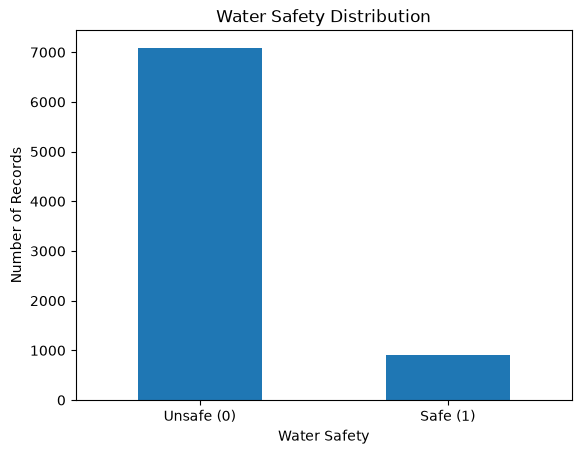

In [18]:
import matplotlib.pyplot as plt

df["is_safe"].value_counts().plot(
    kind="bar",
    xlabel="Water Safety",
    ylabel="Number of Records",
    title="Water Safety Distribution"
)

plt.xticks([0, 1], ["Unsafe (0)", "Safe (1)"], rotation=0)
plt.show()

In [19]:
print("Minimum values:")
print(df.drop("is_safe", axis=1).min())

print("\nMaximum values:")
print(df.drop("is_safe", axis=1).max())

Minimum values:
aluminium      0.00
ammonia       -0.08
arsenic        0.00
barium         0.00
cadmium        0.00
chloramine     0.00
chromium       0.00
copper         0.00
flouride       0.00
bacteria       0.00
viruses        0.00
lead           0.00
nitrates       0.00
nitrites       0.00
mercury        0.00
perchlorate    0.00
radium         0.00
selenium       0.00
silver         0.00
uranium        0.00
dtype: float64

Maximum values:
aluminium       5.05
ammonia        29.84
arsenic         1.05
barium          4.94
cadmium         0.13
chloramine      8.68
chromium        0.90
copper          2.00
flouride        1.50
bacteria        1.00
viruses         1.00
lead            0.20
nitrates       19.83
nitrites        2.93
mercury         0.01
perchlorate    60.01
radium          7.99
selenium        0.10
silver          0.50
uranium         0.09
dtype: float64


In [20]:
negative_ammonia = df[df["ammonia"] < 0]

print("Negative ammonia records:")
display(negative_ammonia)

print("Total negative records:", len(negative_ammonia))

Negative ammonia records:


,aluminium,ammonia,arsenic,barium,cadmium,chloramine,chromium,copper,flouride,bacteria,...,lead,nitrates,nitrites,mercury,perchlorate,radium,selenium,silver,uranium,is_safe
1503,2.82,-0.01,0.47,1.55,0.11,5.79,0.54,1.95,0.56,0.00,...,0.006,16.73,2.04,0.009,29.20,4.31,0.01,0.06,0.01,1
1552,1.60,-0.07,0.95,1.36,0.04,0.40,0.85,0.58,0.34,0.00,...,0.183,5.02,1.42,0.007,6.99,6.53,0.07,0.27,0.05,0
1569,1.92,-0.03,0.66,3.96,0.08,6.19,0.37,1.11,0.61,0.00,...,0.178,12.43,2.05,0.008,6.65,3.83,0.06,0.33,0.07,0
1698,2.99,-0.08,0.41,4.65,0.12,3.55,0.30,1.79,1.31,0.78,...,0.065,15.54,1.93,0.003,11.15,2.89,0.05,0.40,0.09,0
1891,2.59,-0.01,1.01,3.57,0.11,1.34,0.26,1.80,0.72,0.57,...,0.088,10.09,1.59,0.009,36.75,7.70,0.03,0.34,0.02,0
3503,0.04,-0.01,0.33,1.63,0.09,5.57,0.54,0.05,0.56,0.94,...,0.001,15.95,2.19,0.009,29.09,4.31,0.01,0.06,0.01,1
3552,0.10,-0.07,0.62,1.59,0.11,0.26,0.85,0.01,0.34,0.53,...,0.001,5.02,1.34,0.007,6.89,6.53,0.07,0.27,0.05,0
3569,0.19,-0.03,0.09,3.94,0.05,6.26,0.37,0.02,0.61,0.73,...,0.001,12.94,2.09,0.008,6.88,3.83,0.06,0.33,0.07,0
3698,0.01,-0.08,0.20,4.53,0.09,3.17,0.30,0.08,1.31,0.78,...,0.001,16.00,1.61,0.003,11.26,2.89,0.05,0.40,0.09,0
3891,0.11,-0.01,0.62,3.80,0.10,1.38,0.26,0.05,0.72,0.57,...,0.088,10.26,1.53,0.009,36.78,7.70,0.03,0.34,0.02,0


Total negative records: 10


In [21]:
negative_ammonia = df[df["ammonia"] < 0]

negative_ammonia.to_csv(
    "negative_ammonia_records.csv",
    index=False
)

print("Negative records saved successfully!")
print("Total records:", len(negative_ammonia))

Negative records saved successfully!
Total records: 10


In [22]:
print("Total duplicate records:", df.duplicated().sum())

print("Current dataset shape:", df.shape)

Total duplicate records: 0
Current dataset shape: (7996, 21)


In [23]:
print("Negative values in each parameter:\n")

for column in df.columns:
    if column != "is_safe":
        count = (df[column] < 0).sum()

        if count > 0:
            print(column, ":", count)

Negative values in each parameter:

ammonia : 10


In [24]:
correlation = df.corr()

print(correlation)

             aluminium   ammonia   arsenic    barium   cadmium  chloramine  \
aluminium     1.000000  0.067369  0.225725  0.294091 -0.099902    0.369221   
ammonia       0.067369  1.000000  0.046783  0.070099 -0.006422    0.104775   
arsenic       0.225725  0.046783  1.000000  0.362925  0.334782    0.356509   
barium        0.294091  0.070099  0.362925  1.000000 -0.037901    0.446869   
cadmium      -0.099902 -0.006422  0.334782 -0.037901  1.000000   -0.144366   
chloramine    0.369221  0.104775  0.356509  0.446869 -0.144366    1.000000   
chromium      0.353134  0.124782  0.312421  0.415937 -0.157716    0.555846   
copper        0.168569  0.015953 -0.036488  0.065277 -0.109252    0.118975   
flouride     -0.009877 -0.028221  0.003731 -0.018637  0.005005    0.004254   
bacteria     -0.078324  0.063603  0.035642  0.101304 -0.092133    0.154443   
viruses      -0.071040  0.105856  0.011596 -0.002429  0.021255    0.003432   
lead          0.020957 -0.037065 -0.087669 -0.042829 -0.035313  

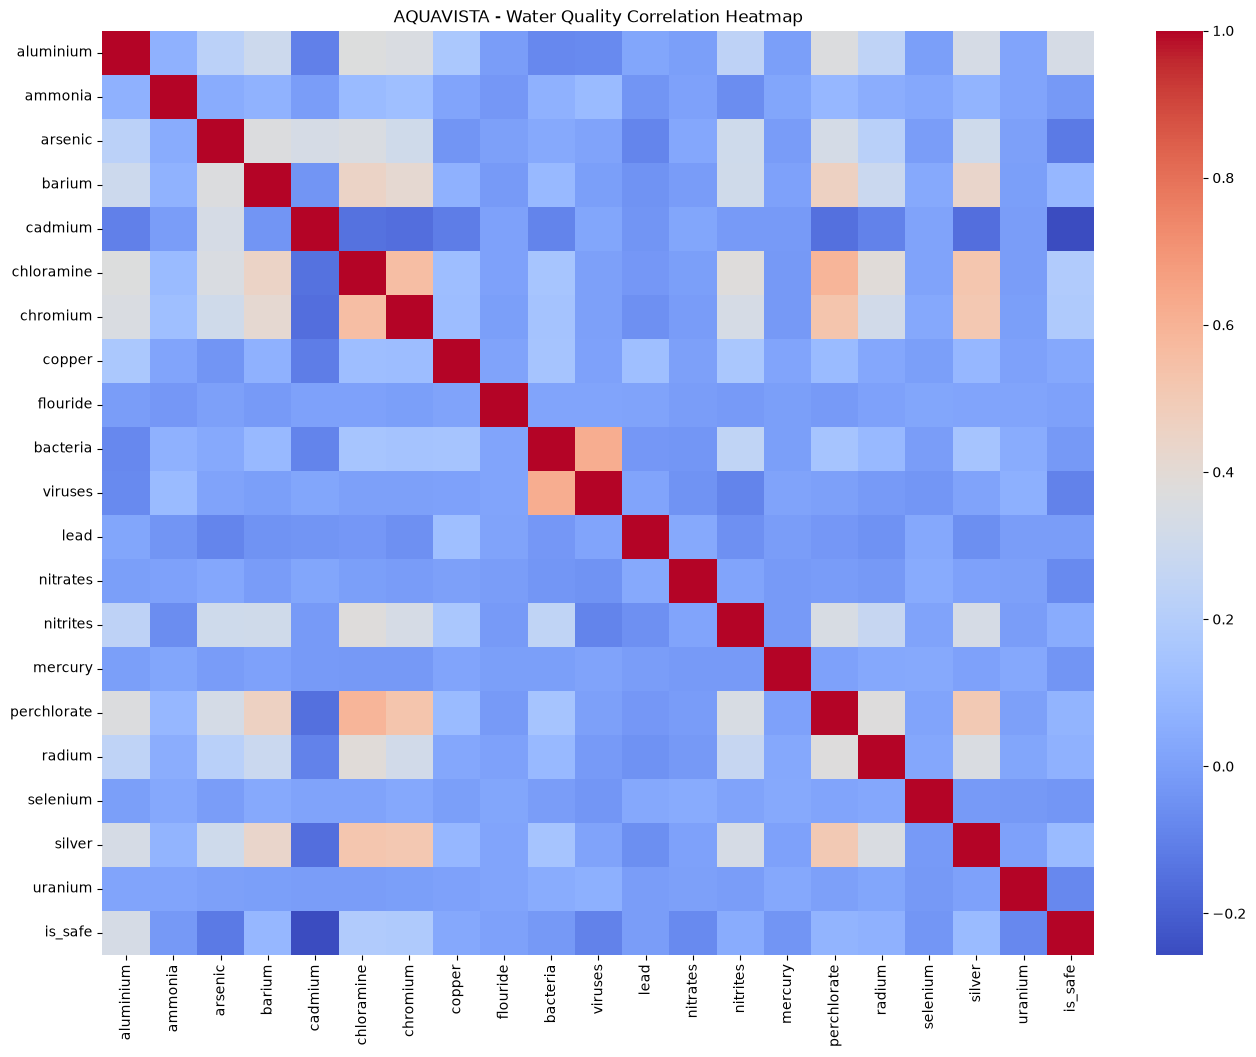

In [27]:
import seaborn as sns
import matplotlib.pyplot as plt

plt.figure(figsize=(16, 12))

sns.heatmap(
    correlation,
    cmap="coolwarm",
    annot=False
)

plt.title("AQUAVISTA - Water Quality Correlation Heatmap")
plt.show()

In [28]:
target_correlation = df.corr()["is_safe"].drop("is_safe")

target_correlation = target_correlation.sort_values()

print("Correlation of parameters with water safety:")
print(target_correlation)

Correlation of parameters with water safety:
cadmium       -0.256034
arsenic       -0.123362
viruses       -0.097040
uranium       -0.075619
nitrates      -0.072100
mercury       -0.036817
selenium      -0.030923
ammonia       -0.022919
bacteria      -0.022077
lead          -0.009970
flouride       0.006550
copper         0.029498
nitrites       0.046986
radium         0.064743
perchlorate    0.075735
barium         0.090858
silver         0.102813
chromium       0.182306
chloramine     0.186704
aluminium      0.333974
Name: is_safe, dtype: float64


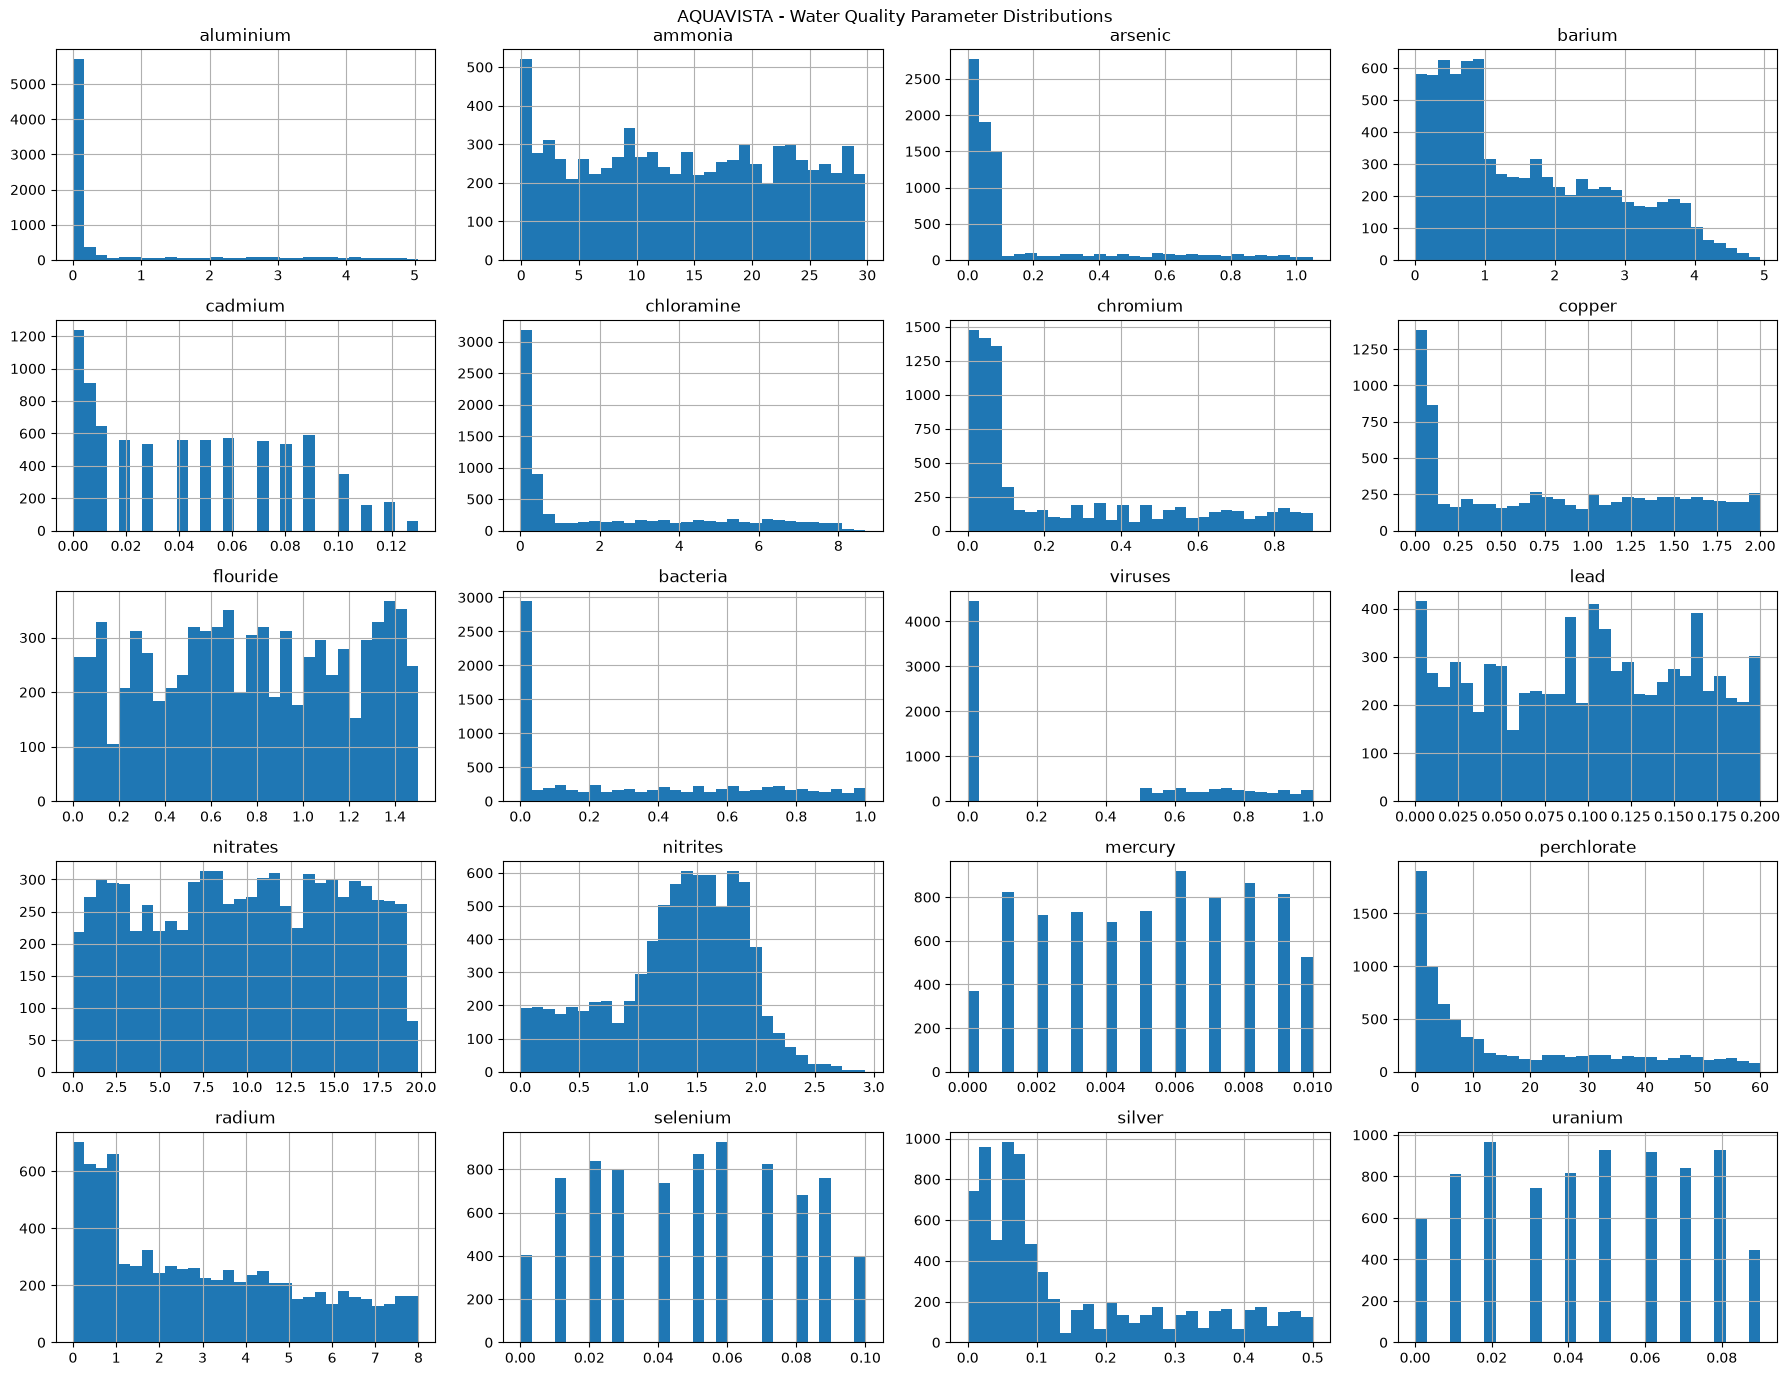

In [29]:
import matplotlib.pyplot as plt

df.drop("is_safe", axis=1).hist(
    figsize=(18, 14),
    bins=30
)

plt.suptitle("AQUAVISTA - Water Quality Parameter Distributions")

plt.tight_layout()
plt.show()

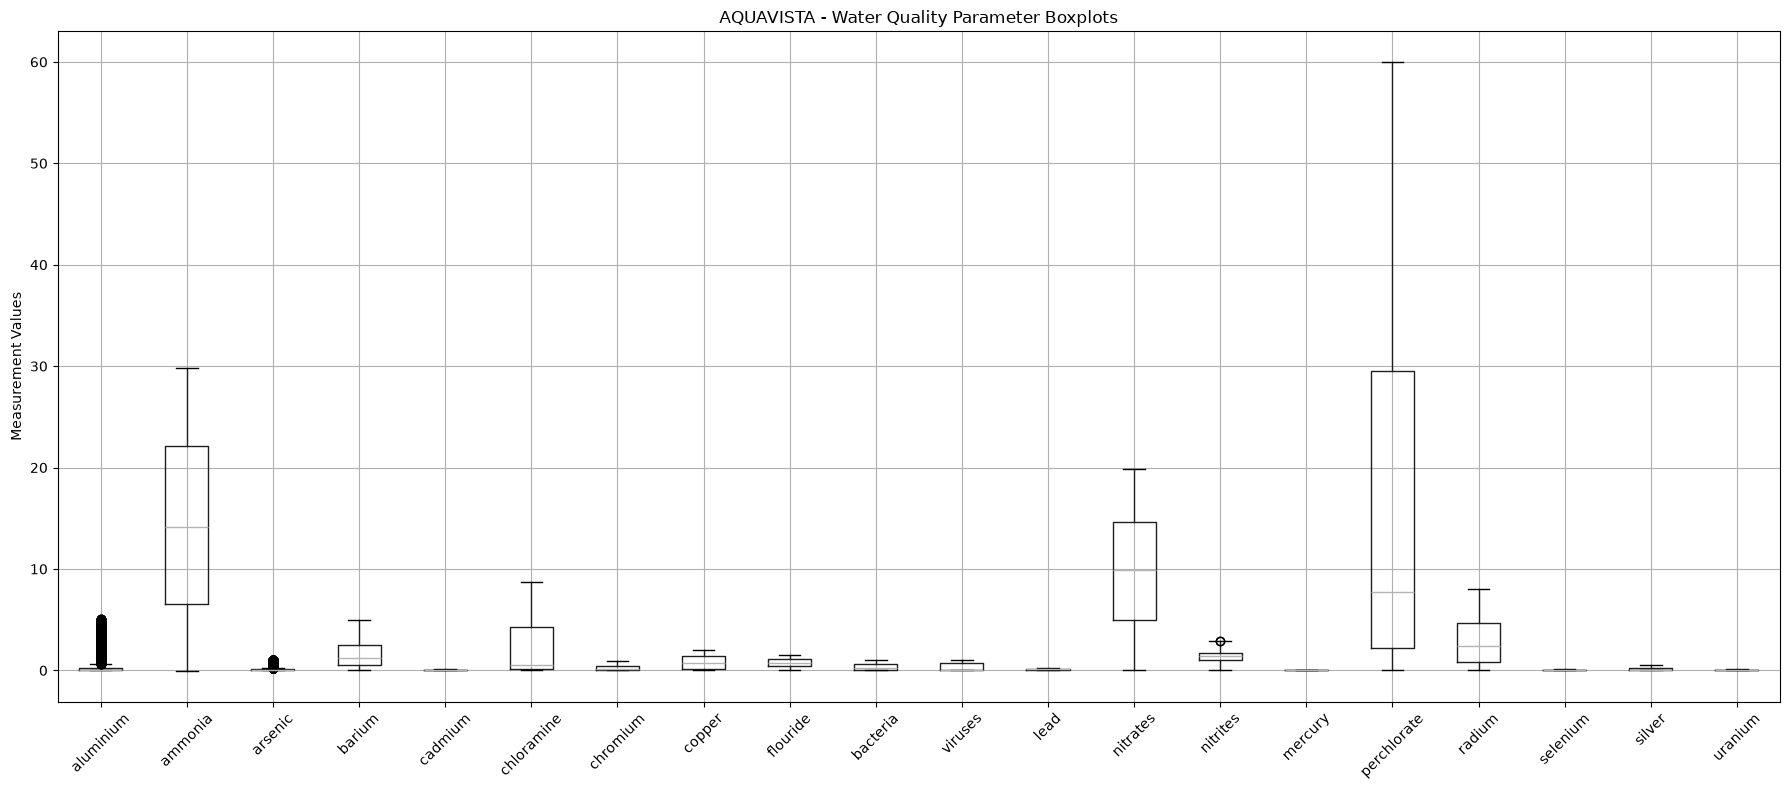

In [30]:
import matplotlib.pyplot as plt

plt.figure(figsize=(18, 8))

df.drop("is_safe", axis=1).boxplot()

plt.title("AQUAVISTA - Water Quality Parameter Boxplots")
plt.xticks(rotation=45)
plt.ylabel("Measurement Values")
plt.tight_layout()
plt.show()

In [31]:
print("Potential outliers in each parameter:\n")

for column in df.columns:
    if column != "is_safe":

        Q1 = df[column].quantile(0.25)
        Q3 = df[column].quantile(0.75)

        IQR = Q3 - Q1

        lower_limit = Q1 - 1.5 * IQR
        upper_limit = Q3 + 1.5 * IQR

        outliers = df[
            (df[column] < lower_limit) |
            (df[column] > upper_limit)
        ]

        print(column, ":", len(outliers))

Potential outliers in each parameter:

aluminium : 1731
ammonia : 0
arsenic : 1634
barium : 0
cadmium : 0
chloramine : 0
chromium : 0
copper : 0
flouride : 0
bacteria : 0
viruses : 0
lead : 0
nitrates : 0
nitrites : 2
mercury : 0
perchlorate : 0
radium : 0
selenium : 0
silver : 0
uranium : 0


In [32]:
for column in ["aluminium", "arsenic", "nitrites"]:

    Q1 = df[column].quantile(0.25)
    Q3 = df[column].quantile(0.75)

    IQR = Q3 - Q1

    lower_limit = Q1 - 1.5 * IQR
    upper_limit = Q3 + 1.5 * IQR

    outliers = df[
        (df[column] < lower_limit) |
        (df[column] > upper_limit)
    ]

    print("\nParameter:", column)
    print("Lower limit:", lower_limit)
    print("Upper limit:", upper_limit)
    print("Minimum flagged value:", outliers[column].min())
    print("Maximum flagged value:", outliers[column].max())
    print("Number of flagged records:", len(outliers))


Parameter: aluminium
Lower limit: -0.32000000000000006
Upper limit: 0.6400000000000001
Minimum flagged value: 0.65
Maximum flagged value: 5.05
Number of flagged records: 1731

Parameter: arsenic
Lower limit: -0.07500000000000001
Upper limit: 0.20500000000000002
Minimum flagged value: 0.21
Maximum flagged value: 1.05
Number of flagged records: 1634

Parameter: nitrites
Lower limit: -0.14000000000000012
Upper limit: 2.9000000000000004
Minimum flagged value: 2.92
Maximum flagged value: 2.93
Number of flagged records: 2


In [33]:
df.to_csv("classification_dataset_preprocessed.csv", index=False)

print("Dataset saved successfully!")
print("Total records:", df.shape[0])
print("Total columns:", df.shape[1])

Dataset saved successfully!
Total records: 7996
Total columns: 21


In [34]:
X = df.drop("is_safe", axis=1)

y = df["is_safe"]

print("Input features (X):", X.shape)
print("Target (y):", y.shape)

print("\nInput feature names:")
print(X.columns.tolist())

print("\nTarget distribution:")
print(y.value_counts())

Input features (X): (7996, 20)
Target (y): (7996,)

Input feature names:
['aluminium', 'ammonia', 'arsenic', 'barium', 'cadmium', 'chloramine', 'chromium', 'copper', 'flouride', 'bacteria', 'viruses', 'lead', 'nitrates', 'nitrites', 'mercury', 'perchlorate', 'radium', 'selenium', 'silver', 'uranium']

Target distribution:
is_safe
0    7084
1     912
Name: count, dtype: int64


In [38]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("Training features:", X_train.shape)
print("Testing features:", X_test.shape)

print("\nTraining target:")
print(y_train.value_counts())

print("\nTesting target:")
print(y_test.value_counts())

Training features: (6396, 20)
Testing features: (1600, 20)

Training target:
is_safe
0    5666
1     730
Name: count, dtype: int64

Testing target:
is_safe
0    1418
1     182
Name: count, dtype: int64


In [36]:
import scipy
import sklearn

print("SciPy version:", scipy.__version__)
print("Scikit-learn version:", sklearn.__version__)

SciPy version: 1.18.0
Scikit-learn version: 1.9.0


In [37]:
from sklearn.model_selection import train_test_split

print("Train-test split imported successfully!")

Train-test split imported successfully!


In [39]:
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)

X_test_scaled = scaler.transform(X_test)

print("Scaled training data:", X_train_scaled.shape)
print("Scaled testing data:", X_test_scaled.shape)

Scaled training data: (6396, 20)
Scaled testing data: (1600, 20)


In [40]:
from sklearn.linear_model import LogisticRegression

model_lr = LogisticRegression(
    max_iter=1000,
    random_state=42
)

model_lr.fit(X_train_scaled, y_train)

print("Logistic Regression model trained successfully!")

Logistic Regression model trained successfully!


In [41]:
y_pred_lr = model_lr.predict(X_test_scaled)

print("Predictions generated successfully!")
print("First 20 predictions:")
print(y_pred_lr[:20])

Predictions generated successfully!
First 20 predictions:
[0 1 0 0 0 0 0 1 0 1 0 0 0 0 0 0 0 0 0 0]


In [42]:
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix

accuracy = accuracy_score(y_test, y_pred_lr)

print("Logistic Regression Accuracy:", accuracy)

print("\nClassification Report:")
print(classification_report(y_test, y_pred_lr))

print("\nConfusion Matrix:")
print(confusion_matrix(y_test, y_pred_lr))

Logistic Regression Accuracy: 0.90875

Classification Report:
              precision    recall  f1-score   support

           0       0.92      0.98      0.95      1418
           1       0.71      0.33      0.45       182

    accuracy                           0.91      1600
   macro avg       0.82      0.66      0.70      1600
weighted avg       0.90      0.91      0.89      1600


Confusion Matrix:
[[1394   24]
 [ 122   60]]


In [43]:
from sklearn.tree import DecisionTreeClassifier

model_dt = DecisionTreeClassifier(
    random_state=42,
    class_weight="balanced"
)

model_dt.fit(X_train, y_train)

print("Decision Tree model trained successfully!")

Decision Tree model trained successfully!


In [44]:
y_pred_dt = model_dt.predict(X_test)

print("Decision Tree predictions generated!")
print("First 20 predictions:")
print(y_pred_dt[:20])

Decision Tree predictions generated!
First 20 predictions:
[0 0 0 0 0 0 0 1 0 1 0 0 0 0 0 0 0 0 0 0]


In [45]:
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix

accuracy_dt = accuracy_score(y_test, y_pred_dt)

print("Decision Tree Accuracy:", accuracy_dt)

print("\nClassification Report:")
print(classification_report(y_test, y_pred_dt))

print("\nConfusion Matrix:")
print(confusion_matrix(y_test, y_pred_dt))

Decision Tree Accuracy: 0.958125

Classification Report:
              precision    recall  f1-score   support

           0       0.97      0.98      0.98      1418
           1       0.83      0.79      0.81       182

    accuracy                           0.96      1600
   macro avg       0.90      0.89      0.89      1600
weighted avg       0.96      0.96      0.96      1600


Confusion Matrix:
[[1389   29]
 [  38  144]]


In [46]:
from sklearn.ensemble import RandomForestClassifier

model_rf = RandomForestClassifier(
    n_estimators=200,
    random_state=42,
    class_weight="balanced",
    n_jobs=-1
)

model_rf.fit(X_train, y_train)

print("Random Forest model trained successfully!")

Random Forest model trained successfully!


In [47]:
y_pred_rf = model_rf.predict(X_test)

print("Random Forest predictions generated!")
print("First 20 predictions:")
print(y_pred_rf[:20])

Random Forest predictions generated!
First 20 predictions:
[0 0 0 0 0 0 0 1 0 1 0 0 0 0 0 0 0 0 0 0]


In [48]:
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix

accuracy_rf = accuracy_score(y_test, y_pred_rf)

print("Random Forest Accuracy:", accuracy_rf)

print("\nClassification Report:")
print(classification_report(y_test, y_pred_rf))

print("\nConfusion Matrix:")
print(confusion_matrix(y_test, y_pred_rf))


Random Forest Accuracy: 0.9575

Classification Report:
              precision    recall  f1-score   support

           0       0.97      0.98      0.98      1418
           1       0.83      0.79      0.81       182

    accuracy                           0.96      1600
   macro avg       0.90      0.89      0.89      1600
weighted avg       0.96      0.96      0.96      1600


Confusion Matrix:
[[1388   30]
 [  38  144]]


In [49]:
#OVER FITTING CHECKING
from sklearn.metrics import accuracy_score

train_predictions_dt = model_dt.predict(X_train)
test_predictions_dt = model_dt.predict(X_test)

train_accuracy_dt = accuracy_score(y_train, train_predictions_dt)
test_accuracy_dt = accuracy_score(y_test, test_predictions_dt)

print("Decision Tree Training Accuracy:", train_accuracy_dt)
print("Decision Tree Testing Accuracy:", test_accuracy_dt)
print("Accuracy Difference:", train_accuracy_dt - test_accuracy_dt)

Decision Tree Training Accuracy: 1.0
Decision Tree Testing Accuracy: 0.958125
Accuracy Difference: 0.041874999999999996


In [50]:
train_predictions_rf = model_rf.predict(X_train)
test_predictions_rf = model_rf.predict(X_test)

train_accuracy_rf = accuracy_score(y_train, train_predictions_rf)
test_accuracy_rf = accuracy_score(y_test, test_predictions_rf)

print("Random Forest Training Accuracy:", train_accuracy_rf)
print("Random Forest Testing Accuracy:", test_accuracy_rf)
print("Accuracy Difference:", train_accuracy_rf - test_accuracy_rf)

Random Forest Training Accuracy: 0.9992182614133833
Random Forest Testing Accuracy: 0.9575
Accuracy Difference: 0.041718261413383306


In [52]:
#CROSS VALIDATION
from sklearn.model_selection import cross_val_score

cv_scores_dt = cross_val_score(
    model_dt,
    X_train,
    y_train,
    cv=5,
    scoring="accuracy"
)

print("Decision Tree Cross-validation scores:")
print(cv_scores_dt)

print("\nMean CV Accuracy:", cv_scores_dt.mean())
print("Standard Deviation:", cv_scores_dt.std())


Decision Tree Cross-validation scores:
[0.95546875 0.96716185 0.95777952 0.95934324 0.95543393]

Mean CV Accuracy: 0.9590374560203283
Standard Deviation: 0.004322098075998608


In [53]:
cv_scores_rf = cross_val_score(
    model_rf,
    X_train,
    y_train,
    cv=5,
    scoring="accuracy"
)

print("Random Forest Cross-validation scores:")
print(cv_scores_rf)

print("\nMean CV Accuracy:", cv_scores_rf.mean())
print("Standard Deviation:", cv_scores_rf.std())

Random Forest Cross-validation scores:
[0.953125   0.95934324 0.95543393 0.95308835 0.95699765]

Mean CV Accuracy: 0.9555976348709929
Standard Deviation: 0.0023844001382277453


In [54]:
# HYPERTUNNING DECISON TREE
from sklearn.tree import DecisionTreeClassifier

model_dt_tuned = DecisionTreeClassifier(
    max_depth=10,
    min_samples_split=10,
    min_samples_leaf=5,
    random_state=42,
    class_weight="balanced"
)

model_dt_tuned.fit(X_train, y_train)

print("Tuned Decision Tree trained successfully!")

Tuned Decision Tree trained successfully!


In [55]:
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix

y_pred_dt_tuned = model_dt_tuned.predict(X_test)

train_acc_tuned = accuracy_score(
    y_train,
    model_dt_tuned.predict(X_train)
)

test_acc_tuned = accuracy_score(y_test, y_pred_dt_tuned)

print("Training Accuracy:", train_acc_tuned)
print("Testing Accuracy:", test_acc_tuned)
print("Accuracy Difference:", train_acc_tuned - test_acc_tuned)

print("\nClassification Report:")
print(classification_report(y_test, y_pred_dt_tuned))

print("\nConfusion Matrix:")
print(confusion_matrix(y_test, y_pred_dt_tuned))

Training Accuracy: 0.9668542839274546
Testing Accuracy: 0.951875
Accuracy Difference: 0.014979283927454623

Classification Report:
              precision    recall  f1-score   support

           0       0.99      0.96      0.97      1418
           1       0.73      0.91      0.81       182

    accuracy                           0.95      1600
   macro avg       0.86      0.93      0.89      1600
weighted avg       0.96      0.95      0.95      1600


Confusion Matrix:
[[1358   60]
 [  17  165]]


In [56]:
# TUNNING OF RANDOM FOREST 
model_rf_tuned = RandomForestClassifier(
    n_estimators=200,
    max_depth=10,
    min_samples_split=10,
    min_samples_leaf=5,
    random_state=42,
    class_weight="balanced",
    n_jobs=-1
)

model_rf_tuned.fit(X_train, y_train)

print("Tuned Random Forest trained successfully!")

Tuned Random Forest trained successfully!


In [57]:
y_pred_rf_tuned = model_rf_tuned.predict(X_test)

train_acc_rf_tuned = accuracy_score(
    y_train,
    model_rf_tuned.predict(X_train)
)

test_acc_rf_tuned = accuracy_score(
    y_test,
    y_pred_rf_tuned
)

print("Training Accuracy:", train_acc_rf_tuned)
print("Testing Accuracy:", test_acc_rf_tuned)
print("Accuracy Difference:", train_acc_rf_tuned - test_acc_rf_tuned)

print("\nClassification Report:")
print(classification_report(y_test, y_pred_rf_tuned))

print("\nConfusion Matrix:")
print(confusion_matrix(y_test, y_pred_rf_tuned))

Training Accuracy: 0.957942464040025
Testing Accuracy: 0.9525
Accuracy Difference: 0.005442464040025019

Classification Report:
              precision    recall  f1-score   support

           0       0.99      0.96      0.97      1418
           1       0.73      0.91      0.81       182

    accuracy                           0.95      1600
   macro avg       0.86      0.93      0.89      1600
weighted avg       0.96      0.95      0.95      1600


Confusion Matrix:
[[1358   60]
 [  16  166]]


In [58]:
#5- FOLD CROSS- VALIDATION
from sklearn.model_selection import StratifiedKFold, cross_validate

cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

scoring = {
    "accuracy": "accuracy",
    "precision": "precision",
    "recall": "recall",
    "f1": "f1"
}

cv_results_rf_tuned = cross_validate(
    model_rf_tuned,
    X_train,
    y_train,
    cv=cv,
    scoring=scoring
)

for metric in scoring:
    scores = cv_results_rf_tuned["test_" + metric]
    print(f"{metric.capitalize()} Mean:", scores.mean())
    print(f"{metric.capitalize()} Std:", scores.std())
    print()

Accuracy Mean: 0.9418390832681782
Accuracy Std: 0.004701112995350349

Precision Mean: 0.6828188448968897
Precision Std: 0.019954365736082762

Recall Mean: 0.9178082191780822
Recall Std: 0.015618841439714204

F1 Mean: 0.7828700556218553
F1 Std: 0.015029903418866649



In [59]:
import joblib

joblib.dump(model_rf_tuned, "aquavista_random_forest.pkl")

print("Tuned Random Forest model saved successfully!")

Tuned Random Forest model saved successfully!


In [60]:
import pandas as pd
import matplotlib.pyplot as plt

feature_importance = pd.DataFrame({
    "Feature": X_train.columns,
    "Importance": model_rf_tuned.feature_importances_
})

feature_importance = feature_importance.sort_values(
    by="Importance",
    ascending=False
)

print(feature_importance)

        Feature  Importance
0     aluminium    0.184715
4       cadmium    0.166352
2       arsenic    0.084678
5    chloramine    0.073781
15  perchlorate    0.071435
18       silver    0.071195
19      uranium    0.044802
10      viruses    0.042703
13     nitrites    0.039681
12     nitrates    0.035132
6      chromium    0.032670
16       radium    0.028182
9      bacteria    0.027270
7        copper    0.020758
11         lead    0.018857
1       ammonia    0.018176
3        barium    0.016499
17     selenium    0.008528
8      flouride    0.007904
14      mercury    0.006681


In [63]:
from sklearn.inspection import permutation_importance

perm_result = permutation_importance(
    model_rf_tuned,
    X_test,
    y_test,
    n_repeats=10,
    random_state=42,
    scoring="f1",
    n_jobs=-1
)

permutation_df = pd.DataFrame({
    "Feature": X_test.columns,
    "Importance": perm_result.importances_mean,
    "Std": perm_result.importances_std
})

permutation_df = permutation_df.sort_values(
    by="Importance",
    ascending=False
)

print(permutation_df)

        Feature  Importance       Std
4       cadmium    0.265476  0.022018
0     aluminium    0.257083  0.023896
18       silver    0.137533  0.006599
15  perchlorate    0.095929  0.008980
2       arsenic    0.080587  0.012333
19      uranium    0.070593  0.012045
10      viruses    0.042371  0.005823
5    chloramine    0.033143  0.008391
16       radium    0.032199  0.008862
12     nitrates    0.029292  0.009439
9      bacteria    0.028000  0.010133
1       ammonia    0.023941  0.004752
7        copper    0.014522  0.009728
17     selenium    0.013529  0.002744
13     nitrites    0.012871  0.005438
11         lead    0.010882  0.006601
6      chromium    0.007536  0.005277
3        barium    0.004527  0.008202
8      flouride    0.004351  0.002940
14      mercury    0.001436  0.003739


In [64]:
from sklearn.model_selection import cross_validate

scoring = {
    "accuracy": "accuracy",
    "precision": "precision",
    "recall": "recall",
    "f1": "f1",
    "f1_macro": "f1_macro",
    "balanced_accuracy": "balanced_accuracy"
}

cv_dt_results = cross_validate(
    model_dt_tuned,
    X_train,
    y_train,
    cv=cv,
    scoring=scoring
)

for metric in scoring:
    scores = cv_dt_results["test_" + metric]
    print(f"{metric.upper()} Mean:", scores.mean())
    print(f"{metric.upper()} Std:", scores.std())
    print()

ACCURACY Mean: 0.9459051260750588
ACCURACY Std: 0.005652261862250229

PRECISION Mean: 0.7021420244035912
PRECISION Std: 0.025365688591669138

RECALL Mean: 0.9164383561643836
RECALL Std: 0.016999552939713506

F1 Mean: 0.7948033003661908
F1 Std: 0.01803186122187988

F1_MACRO Mean: 0.8818233715171037
F1_MACRO Std: 0.010664611053441058

BALANCED_ACCURACY Mean: 0.9330699356190335
BALANCED_ACCURACY Std: 0.008891902711453662



In [65]:
from sklearn.model_selection import cross_validate

extra_scoring = {
    "f1_macro": "f1_macro",
    "balanced_accuracy": "balanced_accuracy"
}

rf_extra_results = cross_validate(
    model_rf_tuned,
    X_train,
    y_train,
    cv=cv,
    scoring=extra_scoring
)

for metric in extra_scoring:
    scores = rf_extra_results["test_" + metric]
    print(f"{metric.upper()} Mean:", scores.mean())
    print(f"{metric.upper()} Std:", scores.std())

F1_MACRO Mean: 0.8746452403753544
F1_MACRO Std: 0.00887792100695764
BALANCED_ACCURACY Mean: 0.9313716576229322
BALANCED_ACCURACY Std: 0.008054778521362143


In [66]:
import joblib

joblib.dump(
    model_dt_tuned,
    "aquavista_decision_tree.pkl"
)

print("AQUAVISTA classification model saved successfully!")

AQUAVISTA classification model saved successfully!


In [67]:
joblib.dump(
    list(X_train.columns),
    "aquavista_feature_names.pkl"
)

print("Feature names saved successfully!")

Feature names saved successfully!


In [68]:
import joblib
import pandas as pd

loaded_model = joblib.load("aquavista_decision_tree.pkl")
feature_names = joblib.load("aquavista_feature_names.pkl")

def predict_water_safety(input_data):
    input_df = pd.DataFrame([input_data], columns=feature_names)

    prediction = loaded_model.predict(input_df)

    if prediction[0] == 1:
        return "Safe"
    else:
        return "Unsafe"

print("AQUAVISTA prediction function is ready!")

AQUAVISTA prediction function is ready!


In [69]:
sample_input = X_test.iloc[0].to_dict()

result = predict_water_safety(sample_input)

print("Predicted Result:", result)
print("Actual Result:", "Safe" if y_test.iloc[0] == 1 else "Unsafe")

Predicted Result: Unsafe
Actual Result: Unsafe


In [70]:
import os

print("Current folder:", os.getcwd())
print(os.listdir())

Current folder: C:\Users\Fatima\OneDrive\Desktop\AQUAVISTA\data\raw
['.ipynb_checkpoints', 'aquavista_combined_results.csv', 'aquavista_decision_tree.pkl', 'aquavista_feature_names.pkl', 'aquavista_random_forest.pkl', 'classification.ipynb', 'classification_dataset_preprocessed.csv', 'negative_ammonia_records.csv', 'RiverWaterQualityOverYears (1).csv', 'unsupervised.ipynb', 'waterQuality1.csv']


In [71]:
import joblib

model = joblib.load("aquavista_decision_tree.pkl")

feature_names = joblib.load("aquavista_feature_names.pkl")

print("Model loaded successfully!")
print("Number of input features:", len(feature_names))
print("Input features:", feature_names)

Model loaded successfully!
Number of input features: 20
Input features: ['aluminium', 'ammonia', 'arsenic', 'barium', 'cadmium', 'chloramine', 'chromium', 'copper', 'flouride', 'bacteria', 'viruses', 'lead', 'nitrates', 'nitrites', 'mercury', 'perchlorate', 'radium', 'selenium', 'silver', 'uranium']


In [72]:
%pip install fastapi uvicorn

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 26.2.1 -> 26.3
[notice] To update, run: C:\Users\Fatima\AppData\Local\Python\pythoncore-3.14-64\python.exe -m pip install --upgrade pip


In [73]:
import json

sample_input = X_test.iloc[0].to_dict()

print(json.dumps(sample_input, indent=4))

{
    "aluminium": 3.9,
    "ammonia": 22.64,
    "arsenic": 0.41,
    "barium": 0.34,
    "cadmium": 0.03,
    "chloramine": 7.94,
    "chromium": 0.06,
    "copper": 0.28,
    "flouride": 0.28,
    "bacteria": 0.0,
    "viruses": 0.0,
    "lead": 0.137,
    "nitrates": 18.54,
    "nitrites": 1.55,
    "mercury": 0.009,
    "perchlorate": 13.18,
    "radium": 6.93,
    "selenium": 0.1,
    "silver": 0.26,
    "uranium": 0.02
}


In [74]:
import joblib
import pandas as pd

loaded_model = joblib.load("aquavista_decision_tree.pkl")
feature_names = joblib.load("aquavista_feature_names.pkl")

input_df = pd.DataFrame(
    [sample_input],
    columns=feature_names
)

prediction = loaded_model.predict(input_df)[0]
probabilities = loaded_model.predict_proba(input_df)[0]

print("Prediction:", prediction)
print("Probabilities:", probabilities)
print("Predicted class:", loaded_model.classes_[probabilities.argmax()])

Prediction: 0
Probabilities: [1. 0.]
Predicted class: 0


In [75]:
import joblib
import pandas as pd

model = joblib.load("aquavista_decision_tree.pkl")
feature_names = joblib.load("aquavista_feature_names.pkl")

input_df = pd.DataFrame(
    [{
        "aluminium": 3.9,
        "ammonia": 22.64,
        "arsenic": 0.41,
        "barium": 0.34,
        "cadmium": 0.03,
        "chloramine": 7.94,
        "chromium": 0.06,
        "copper": 0.28,
        "flouride": 0.28,
        "bacteria": 0.0,
        "viruses": 0.0,
        "lead": 0.137,
        "nitrates": 18.54,
        "nitrites": 1.55,
        "mercury": 0.009,
        "perchlorate": 13.18,
        "radium": 6.93,
        "selenium": 0.1,
        "silver": 0.26,
        "uranium": 0.02
    }],
    columns=feature_names
)

print("Prediction:", model.predict(input_df))
print("Probabilities:", model.predict_proba(input_df))

Prediction: [0]
Probabilities: [[1. 0.]]
